In [4]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/retail_daily_demand_dataset.csv")
df.head()

,date,store_id,product_id,category,unit_price,promotion,promotion_discount,stock_on_hand,units_sold
0,2024-01-01,S001,P001,Beverages,35.0,0,0.0,847,34
1,2024-01-02,S001,P001,Beverages,35.0,0,0.0,814,33
2,2024-01-03,S001,P001,Beverages,35.0,0,0.0,789,25
3,2024-01-04,S001,P001,Beverages,35.0,0,0.0,756,33
4,2024-01-05,S001,P001,Beverages,35.0,0,0.0,725,31


In [6]:
print(df.shape)
print(df.columns)
df.info()

(13140, 9)
Index(['date', 'store_id', 'product_id', 'category', 'unit_price', 'promotion',
       'promotion_discount', 'stock_on_hand', 'units_sold'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 13140 entries, 0 to 13139
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                13140 non-null  str    
 1   store_id            13140 non-null  str    
 2   product_id          13140 non-null  str    
 3   category            13140 non-null  str    
 4   unit_price          13140 non-null  float64
 5   promotion           13140 non-null  int64  
 6   promotion_discount  13140 non-null  float64
 7   stock_on_hand       13140 non-null  int64  
 8   units_sold          13140 non-null  int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 924.0 KB


In [7]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

date                  0
store_id              0
product_id            0
category              0
unit_price            0
promotion             0
promotion_discount    0
stock_on_hand         0
units_sold            0
dtype: int64
Duplicates: 0


In [8]:
df.describe()

,unit_price,promotion,promotion_discount,stock_on_hand,units_sold
count,13140.000000,13140.000000,13140.000000,13140.000000,13140.000000
mean,48.666667,0.084627,0.012683,151.999011,28.056925
std,25.204574,0.278337,0.043396,192.989577,17.681032
min,22.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,0.000000,0.000000,24.000000,15.000000
50%,38.500000,0.000000,0.000000,88.000000,27.000000
75%,68.000000,0.000000,0.000000,194.000000,39.000000
max,95.000000,1.000000,0.200000,1370.000000,121.000000


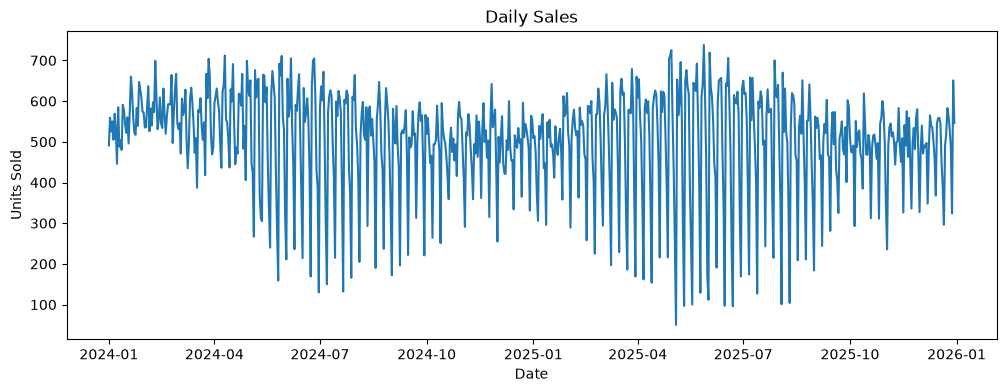

In [9]:
df["date"] = pd.to_datetime(df["date"])

daily_sales = df.groupby("date")["units_sold"].sum()

plt.figure(figsize=(12, 4))
plt.plot(daily_sales)
plt.title("Daily Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.show()

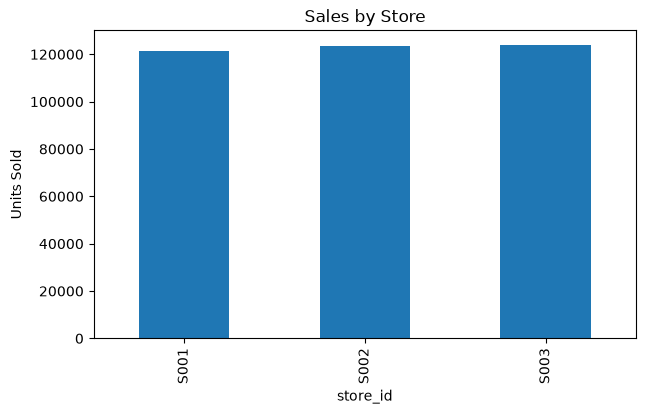

In [10]:
store_sales = df.groupby("store_id")["units_sold"].sum()

store_sales.plot(kind="bar", figsize=(7, 4), title="Sales by Store")
plt.ylabel("Units Sold")
plt.show()

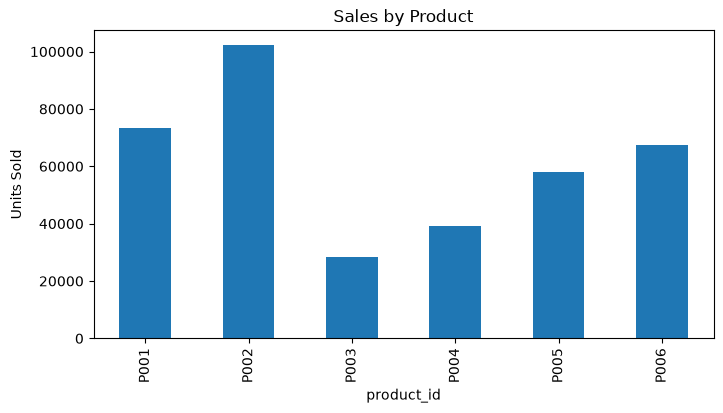

In [11]:
product_sales = df.groupby("product_id")["units_sold"].sum()

product_sales.plot(kind="bar", figsize=(8, 4), title="Sales by Product")
plt.ylabel("Units Sold")
plt.show()

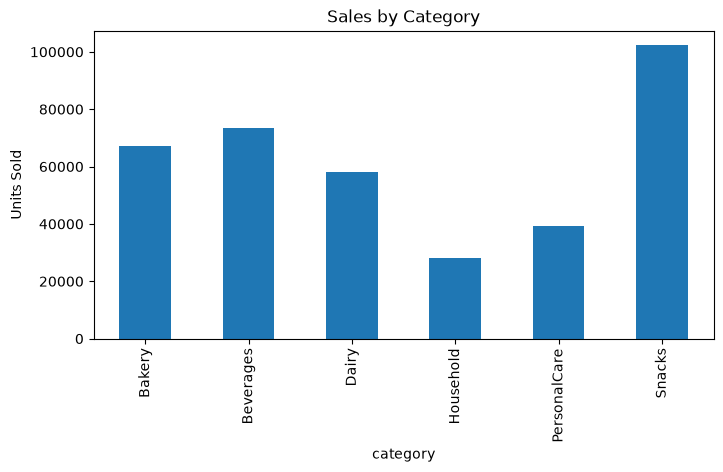

In [12]:
category_sales = df.groupby("category")["units_sold"].sum()

category_sales.plot(kind="bar", figsize=(8, 4), title="Sales by Category")
plt.ylabel("Units Sold")
plt.show()

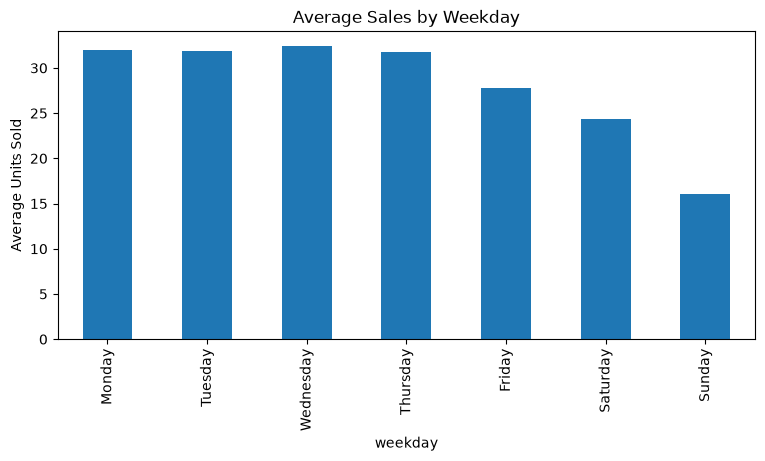

In [13]:
df["weekday"] = df["date"].dt.day_name()
weekday_sales = df.groupby("weekday")["units_sold"].mean()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = weekday_sales.reindex(order)

weekday_sales.plot(kind="bar", figsize=(9, 4), title="Average Sales by Weekday")
plt.ylabel("Average Units Sold")
plt.show()

promotion
0    26.873213
1    40.860612
Name: units_sold, dtype: float64


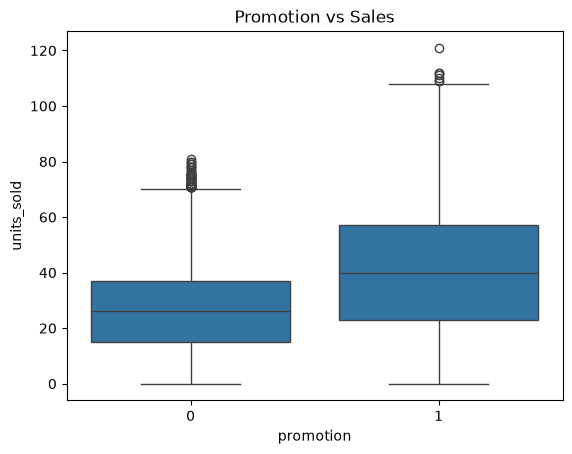

In [14]:
print(df.groupby("promotion")["units_sold"].mean())

sns.boxplot(data=df, x="promotion", y="units_sold")
plt.title("Promotion vs Sales")
plt.show()

Zero stock rows: 2290


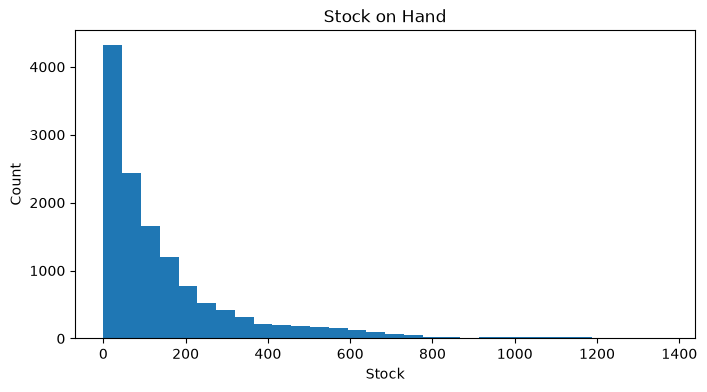

In [15]:
print("Zero stock rows:", (df["stock_on_hand"] == 0).sum())

plt.figure(figsize=(8, 4))
plt.hist(df["stock_on_hand"], bins=30)
plt.title("Stock on Hand")
plt.xlabel("Stock")
plt.ylabel("Count")
plt.show()

In [16]:
df[["unit_price", "promotion", "promotion_discount",
    "stock_on_hand", "units_sold"]].corr()

,unit_price,promotion,promotion_discount,stock_on_hand,units_sold
unit_price,1.000000,0.005714,0.006889,-0.257824,-0.565152
promotion,0.005714,1.000000,0.961208,-0.035460,0.220191
promotion_discount,0.006889,0.961208,1.000000,-0.035323,0.213408
stock_on_hand,-0.257824,-0.035460,-0.035323,1.000000,0.286848
units_sold,-0.565152,0.220191,0.213408,0.286848,1.000000
